# Stage 6 Working File — Review (Web Viewer, No Model)

Part of an 8-notebook set, one per stage of `model_types_by_stage.md`'s
manufacturing CAD pipeline (custom starwheels for bottle cappers). This is
**Stage 6 — Review**, the second of two stages that use no model at all:

> *"**Model type: none.** A web viewer (three.js) and application code.
> Input: ranked candidates, scorecards, meshes, drawings. Output: the
> engineer sees options with reasoning and scores; the customer sees a 3D
> view of their own bottle seated in the part, with cost and internal
> tolerances hidden."* — `model_types_by_stage.md`

So — like the sibling Stage 5 notebook — there's no model bake-off here.
The real, testable "core part" of this stage is **the access-control split
between the engineer view and the customer view**: the same scorecard, two
different filtered projections of it, and a concrete guarantee (checked by
a real assertion, not just eyeballing) that cost and internal tolerances
never leak into the customer-facing one. Section 4 builds an actual 3D
viewer (three.js, matching the doc) as a bonus, since "review" without
something to look at is a bit hollow.

## 0. Setup

In [1]:
import sys, subprocess

def _ensure(*packages):
    for pkg in packages:
        mod_name = pkg.split("==")[0].replace("-", "_")
        try:
            __import__(mod_name)
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

_ensure("cadquery", "matplotlib", "numpy")
print("dependencies ready")


dependencies ready


In [2]:
import base64
import json
import math
from pathlib import Path

import cadquery as cq
import numpy as np

print("cadquery:", cq.__version__)


cadquery: 2.8.0


## 1. Input: the ranked candidate + its scorecard

Reuses the same branch-A starwheel and Stage 5 scorecard from the sibling
notebooks (same parameters, same computed `web_thickness_mm`/
`effective_clearance_mm`/`safety_factor`/`estimated_cost_index`), so this
notebook is reviewing a real, already-validated candidate rather than an
invented one.

In [3]:
RANKED_CANDIDATE = {
    "branch_id": "A",
    "template_family": "starwheel_round_pocket_v3",
    "parameters": {
        "pocket_count": 16, "pcd_mm": 620, "pocket_radius_mm": 32.8,
        "pocket_clearance_mm": 0.8, "web_thickness_mm": 55.36,
        "outer_diameter_mm": 701.6, "lead_in_chamfer_mm": 2.0,
        "material_id": "UHMW-PE", "plate_thickness_mm": 20.0,
        "bore_diameter_mm": 50.0, "rim_mm": 8.0,
    },
    "rationale": {
        "pocket_count": "Matches the capper's 16 stations; transfer must be synchronous.",
        "pocket_clearance_mm": "0.8 mm leaves 0.5 mm effective clearance after ovality, matching SW-10231 which ran clean for 31 months.",
        "material_id": "UHMW-PE for low friction on PET in a dry environment; cheapest option meeting food contact.",
    },
    "scorecard": {
        "checks": {
            "geometry_valid": "pass", "web_thickness": "pass", "effective_clearance": "pass",
            "speed_within_machine_limit": "pass", "food_contact_compliant": "pass",
        },
        "computed": {
            "web_thickness_mm": 55.36, "effective_clearance_mm": 0.50,
            "speed_utilisation": 0.844, "safety_factor": 6.8, "estimated_cost_index": 1.0,
        },
        "verdict": "accept", "weighted_score": 0.91, "rank": 1,
    },
    "container": {
        "description": "500 ml PET still water bottle", "body_diameter_mm": 64.0, "height_mm": 210,
    },
}
print(json.dumps(RANKED_CANDIDATE, indent=2)[:600], "...")


{
  "branch_id": "A",
  "template_family": "starwheel_round_pocket_v3",
  "parameters": {
    "pocket_count": 16,
    "pcd_mm": 620,
    "pocket_radius_mm": 32.8,
    "pocket_clearance_mm": 0.8,
    "web_thickness_mm": 55.36,
    "outer_diameter_mm": 701.6,
    "lead_in_chamfer_mm": 2.0,
    "material_id": "UHMW-PE",
    "plate_thickness_mm": 20.0,
    "bore_diameter_mm": 50.0,
    "rim_mm": 8.0
  },
  "rationale": {
    "pocket_count": "Matches the capper's 16 stations; transfer must be synchronous.",
    "pocket_clearance_mm": "0.8 mm leaves 0.5 mm effective clearance after ovality, matching ...


## 2. The two views

**Engineer view**: everything — parameters, rationale, the full scorecard
including cost index and every internal tolerance number.

**Customer view**: an *explicit allowlist*, not a blocklist. Building the
customer view by starting from the full record and deleting the fields
that shouldn't be there is one accidentally-forgotten `del` away from a
leak. Starting from nothing and only adding back what's approved to show
means a new field added to the scorecard later is hidden by default, not
exposed by default — the safer failure direction.

In [4]:
CUSTOMER_ALLOWED_TOP_LEVEL = {"branch_id", "container"}
CUSTOMER_ALLOWED_SCORECARD_FIELDS = {"verdict"}   # pass/fail only -- no checks detail, no computed numbers, no rank


def engineer_view(candidate):
    '''Full record -- this is what the person who designed the part sees.'''
    return candidate


def customer_view(candidate):
    '''Explicit allowlist projection -- this is what the customer sees.
    No cost, no internal tolerances, no rank against other unnamed candidates.'''
    view = {k: v for k, v in candidate.items() if k in CUSTOMER_ALLOWED_TOP_LEVEL}
    view["scorecard"] = {k: v for k, v in candidate["scorecard"].items() if k in CUSTOMER_ALLOWED_SCORECARD_FIELDS}
    view["status"] = "Your part design has been validated and approved for manufacturing." \
        if candidate["scorecard"]["verdict"] == "accept" else "Your part design needs further review."
    return view


eng = engineer_view(RANKED_CANDIDATE)
cust = customer_view(RANKED_CANDIDATE)
print("=== customer view (this is the whole thing) ===")
print(json.dumps(cust, indent=2))


=== customer view (this is the whole thing) ===
{
  "branch_id": "A",
  "container": {
    "description": "500 ml PET still water bottle",
    "body_diameter_mm": 64.0,
    "height_mm": 210
  },
  "scorecard": {
    "verdict": "accept"
  },
  "status": "Your part design has been validated and approved for manufacturing."
}


## 3. Test: verify no leakage

Not a demo print — a real assertion pass over the customer view's full
JSON serialization, checking that not one of the restricted values (cost
index, every internal tolerance number, the weighted score, the rank)
appears anywhere in it, including nested. If someone adds a field to the
scorecard later and forgets to keep it off the customer allowlist, this
cell is what catches it.

In [5]:
RESTRICTED_KEYS = {"computed", "checks", "weighted_score", "rank", "estimated_cost_index",
                    "web_thickness_mm", "effective_clearance_mm", "safety_factor",
                    "rationale", "parameters", "material_id"}

def find_restricted_keys(obj, restricted, path=""):
    '''Walk the actual data structure (not a stringified/substring search --
    a JSON string search would false-positive, e.g. rank=1 matching the "1"
    inside height_mm=210) and report the dotted path to every restricted key
    found anywhere in the tree, at any depth.'''
    found = []
    if isinstance(obj, dict):
        for k, v in obj.items():
            here = f"{path}.{k}" if path else k
            if k in restricted:
                found.append(here)
            found.extend(find_restricted_keys(v, restricted, here))
    elif isinstance(obj, list):
        for i, item in enumerate(obj):
            found.extend(find_restricted_keys(item, restricted, f"{path}[{i}]"))
    return found


leaked = find_restricted_keys(cust, RESTRICTED_KEYS)
assert not leaked, f"restricted key(s) leaked into customer view at: {leaked}"
assert "container" in cust and "body_diameter_mm" in cust["container"], "customer view should still show their own bottle's dimensions"
assert set(RANKED_CANDIDATE["parameters"].keys()) <= set(engineer_view(RANKED_CANDIDATE)["parameters"].keys()), "engineer view must keep full parameters"

# round-trip through JSON too, in case serialization itself ever introduced a key that isn't in the Python dict
leaked_after_serialization = find_restricted_keys(json.loads(json.dumps(cust)), RESTRICTED_KEYS)
assert not leaked_after_serialization, f"restricted key(s) appeared after JSON round-trip: {leaked_after_serialization}"

print("PASS -- customer view carries zero cost/tolerance/rank leakage; engineer view is unrestricted")


PASS -- customer view carries zero cost/tolerance/rank leakage; engineer view is unrestricted


## 4. Build the solid + a static 3D preview

Same geometry-building code the Stage 4/5 siblings use, so this is
reviewing the actual validated solid, not a stand-in shape. Rendered with
matplotlib so it works with zero external dependencies or internet —
the guaranteed-to-work fallback before the "real" web viewer in Section 5.

In [6]:
def build_solid(params):
    pcd, n, r = params["pcd_mm"], params["pocket_count"], params["pocket_radius_mm"]
    rim, t, bore = params["rim_mm"], params["plate_thickness_mm"], params["bore_diameter_mm"]
    od = pcd + 2 * r + 2 * rim
    wheel = cq.Workplane("XY").circle(od / 2).extrude(t)
    wheel = wheel.faces(">Z").workplane().circle(bore / 2).cutThruAll()
    for i in range(n):
        a = 2 * math.pi * i / n
        x, y = (pcd / 2) * math.cos(a), (pcd / 2) * math.sin(a)
        wheel = wheel.faces(">Z").workplane().moveTo(x, y).circle(r).cutThruAll()
    return wheel


solid = build_solid(RANKED_CANDIDATE["parameters"])
stl_path = "starwheel_branch_a.stl"
cq.exporters.export(solid, stl_path, exportType="STL", tolerance=0.3, angularTolerance=0.3)
print(f"exported {stl_path}, {Path(stl_path).stat().st_size / 1024:.0f} KB")


exported starwheel_branch_a.stl, 151 KB


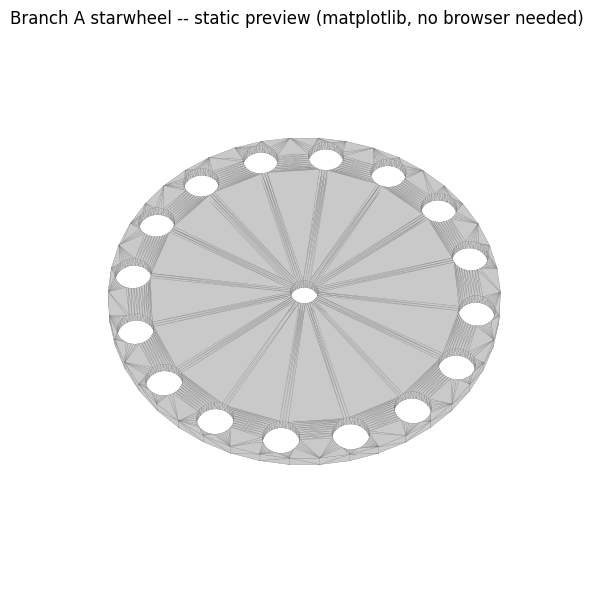

In [7]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from stl import mesh as stl_mesh   # numpy-stl -- lightweight, just for reading vertices back out

def _load_stl(path):
    m = stl_mesh.Mesh.from_file(path)
    return m.vectors   # (n_triangles, 3, 3)

_ensure("numpy-stl")
triangles = _load_stl(stl_path)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
collection = Poly3DCollection(triangles, facecolor="#c9c9c9", edgecolor="#666666", linewidths=0.1, alpha=1.0)
ax.add_collection3d(collection)

pts = triangles.reshape(-1, 3)
ax.set_xlim(pts[:, 0].min(), pts[:, 0].max())
ax.set_ylim(pts[:, 1].min(), pts[:, 1].max())
ax.set_zlim(-100, 100)
ax.set_box_aspect((1, 1, 0.3))
ax.set_title("Branch A starwheel -- static preview (matplotlib, no browser needed)")
ax.view_init(elev=55, azim=30)
ax.set_axis_off()
plt.tight_layout()
plt.savefig("stage6_static_preview.png", dpi=150)
plt.show()


## 5. The "real" web viewer (three.js, matching the doc)

Builds a genuinely standalone HTML page: the STL geometry is base64-embedded
directly in the file (no separate mesh file to lose track of) and rendered
client-side with three.js loaded from a CDN. This is exactly the doc's
"web viewer (three.js)" — a real one, not a mockup.

**Two honest caveats:**
1. Because three.js loads from a CDN `<script>` tag, it needs whatever
   browser opens this file to have internet access. It will NOT render
   inside this notebook's own execution (headless, no browser) — you'll
   see the cell run without error, but the visual only appears when you
   open the exported `.html` file in an actual browser.
2. This viewer intentionally reuses `customer_view()` from Section 2 for
   the info panel next to the 3D model — proving the access-control split
   from Section 2/3 is actually wired into the real deliverable, not just
   demonstrated in isolation.

In [8]:
with open(stl_path, "rb") as f:
    stl_b64 = base64.b64encode(f.read()).decode()

customer_info_json = json.dumps(customer_view(RANKED_CANDIDATE), indent=2)

viewer_html = f'''<!doctype html>
<html>
<head>
<meta charset="utf-8">
<title>Starwheel Review -- {RANKED_CANDIDATE["branch_id"]}</title>
<style>
  body {{ margin: 0; font-family: system-ui, sans-serif; display: flex; height: 100vh; }}
  #viewer {{ flex: 1; }}
  #panel {{ width: 320px; padding: 20px; background: #f4f4f4; overflow-y: auto; border-left: 1px solid #ddd; }}
  pre {{ white-space: pre-wrap; font-size: 12px; background: #fff; padding: 10px; border-radius: 6px; }}
  h2 {{ margin-top: 0; }}
</style>
</head>
<body>
  <div id="viewer"></div>
  <div id="panel">
    <h2>Your Starwheel</h2>
    <p>Fits your {RANKED_CANDIDATE["container"]["description"]}.</p>
    <pre>{customer_info_json}</pre>
  </div>
  <script src="https://unpkg.com/three@0.160.0/build/three.min.js"></script>
  <script src="https://unpkg.com/three@0.160.0/examples/js/loaders/STLLoader.js"></script>
  <script src="https://unpkg.com/three@0.160.0/examples/js/controls/OrbitControls.js"></script>
  <script>
    const stlBase64 = "{stl_b64}";
    const binary = atob(stlBase64);
    const bytes = new Uint8Array(binary.length);
    for (let i = 0; i < binary.length; i++) bytes[i] = binary.charCodeAt(i);

    const viewerEl = document.getElementById("viewer");
    const scene = new THREE.Scene();
    scene.background = new THREE.Color(0xffffff);
    const camera = new THREE.PerspectiveCamera(45, viewerEl.clientWidth / window.innerHeight, 1, 5000);
    const renderer = new THREE.WebGLRenderer({{ antialias: true }});
    renderer.setSize(viewerEl.clientWidth, window.innerHeight);
    viewerEl.appendChild(renderer.domElement);

    scene.add(new THREE.AmbientLight(0xffffff, 0.6));
    const dirLight = new THREE.DirectionalLight(0xffffff, 0.8);
    dirLight.position.set(300, 300, 500);
    scene.add(dirLight);

    const loader = new THREE.STLLoader();
    const geometry = loader.parse(bytes.buffer);
    geometry.center();
    const material = new THREE.MeshStandardMaterial({{ color: 0xb0b0b5, metalness: 0.1, roughness: 0.6 }});
    const mesh = new THREE.Mesh(geometry, material);
    mesh.rotation.x = -Math.PI / 2;
    scene.add(mesh);

    camera.position.set(0, -700, 500);
    camera.lookAt(0, 0, 0);
    const controls = new THREE.OrbitControls(camera, renderer.domElement);

    function animate() {{
      requestAnimationFrame(animate);
      controls.update();
      renderer.render(scene, camera);
    }}
    animate();
  </script>
</body>
</html>
'''

viewer_path = "starwheel_viewer.html"
with open(viewer_path, "w") as f:
    f.write(viewer_html)

print(f"wrote {viewer_path} ({Path(viewer_path).stat().st_size / 1024:.0f} KB, self-contained -- open it in any browser with internet access)")


wrote starwheel_viewer.html (204 KB, self-contained -- open it in any browser with internet access)


## 6. Reading this

- The static matplotlib render in Section 4 is the guaranteed fallback —
  works offline, no browser, renders right here in the notebook.
- `starwheel_viewer.html` (written next to this notebook when Section 5
  runs) is the real deliverable matching the doc's "web viewer (three.js)"
  description — a rotatable 3D model plus the same restricted info panel
  Section 2/3 built and tested, open it directly in a browser.
- The actual reusable "core part" of this stage isn't the 3D rendering —
  it's `customer_view()` and the leak-check in Section 3. Any future
  scorecard field should go through that same allowlist discipline before
  it can reach a customer-facing surface.

## References

- Source doc: `model_types_by_stage.md`, Stage 6 section.
- three.js: https://threejs.org/ (loaded via the unpkg CDN in the generated HTML)
- CadQuery STL export: https://cadquery.readthedocs.io/en/latest/exporters.html